This notebook reproduces Fig. 3. We compute the infidelity of the adiabatic transfer in the Landau-Zener problem (see `Fig02-LZ.ipynb`) for the pulses with $n_+=2$ (geometric fast-QUAD), $n_+=3$ (FAQUAD), and $n_+=4$, as a function of the pulse time. Energies are given in units of $x$, and times in units of $\hbar/x$.

In the adiabatic limit, first-order adiabatic perturbation theory gives the amplitude of the excited state at the end of the protocol (for symmetric boundary conditions)
$$
|c_1(t_\mathrm{f})|^2 \simeq \frac{4\tilde{a}(0)^2}{t_\mathrm{f}^2}\sin^2\left(\frac{t_\mathrm{f}\Phi}{2}\right),
$$
such that the infidelity is bounded by the envelope $1-\mathcal{F}\lesssim 4\tilde{a}(0)^2/t_\mathrm{f}^2$ (black dot-dashed lines), and vanishes at the resonances $t_\mathrm{f}=2\pi k/\Phi$, with $k$ an integer (vertical gray dashed lines). Here, $\Phi = \int_0^1 d\tau\, [E_1(\tau) - E_0(\tau)]$ is the time-averaged gap, with $\tau=t/t_\mathrm{f}$, and $\tilde{a}(0)$ is the (rescaled) adiabaticity at the beginning of the protocol,
$$
\tilde{a}(\tau) =\frac{|\langle\psi_0(\tau)|\partial_\tau\psi_1(\tau)\rangle|}{|E_1(\tau) - E_0(\tau)|} = \frac{|\langle\psi_0(\tau)|\partial_\tau \hat{H}|\psi_1(\tau)\rangle|}{|E_1(\tau) - E_0(\tau)|^2}.
$$

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from brokenaxes import brokenaxes
from matplotlib.gridspec import GridSpec
from parameterrun import parameterrun
from scipy.integrate import romb
from tqdm.auto import tqdm

from HQUAD_lib.hamiltonians import lz_problem
from HQUAD_lib.physics_utils import fidelity_LZ
from HQUAD_lib.plotting_utils import add_labels
from HQUAD_lib.QUAD_utils import solve_LZ

In [2]:
x = 1

alphas = np.array([2, 3, 4])
betas = alphas
n_plus = (alphas + betas) / 2

tfs = np.linspace(
    0.1, 120, 500
)  # Increase for higher resolution (2000 values in the manuscript)

In [3]:
def compute_fidelity_total(
    alpha: float, beta: float
) -> tuple[np.ndarray, float, float]:
    z_sol = solve_LZ(alpha, beta, x=x)
    s = np.linspace(0, 1, len(z_sol))

    # Fidelities
    fidelities = np.asarray(
        parameterrun(fidelity_LZ, "tf", tfs, pulse=z_sol, x=x, z0=-10, pbar_leave=False)
    )

    # Period between resonances, 2 pi / Phi
    hypermatrix = np.array([lz_problem(x, z) for z in z_sol])
    eigvalues, eigmodes = np.linalg.eigh(hypermatrix)

    gap = eigvalues[:, 1] - eigvalues[:, 0]
    period = 2 * np.pi / romb(gap, dx=s[1] - s[0])

    # Adiabaticity at the beginning of the protocol (the first point is skipped to avoid the boundary of the gradient)
    d_eigmodes = np.gradient(eigmodes, s, axis=0)
    num = np.abs(eigmodes[1, :, 0].conj() @ d_eigmodes[1, :, 1])
    den = np.abs(eigvalues[1, 0] - eigvalues[1, 1])
    adiabaticity = num / den

    return fidelities, period, adiabaticity

In [4]:
fidelities = np.zeros((len(alphas), len(tfs)))
periods = np.zeros(len(alphas))
adiabaticities = np.zeros(len(alphas))

for i in tqdm(range(len(alphas)), desc="Computing fidelities"):
    fidelities[i], periods[i], adiabaticities[i] = compute_fidelity_total(
        alphas[i], betas[i]
    )

Computing fidelities:   0%|          | 0/3 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/500 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/500 [00:00<?, ?it/s]

fidelity_LZ: [['tf']]:   0%|          | 0/500 [00:00<?, ?it/s]

# Plot

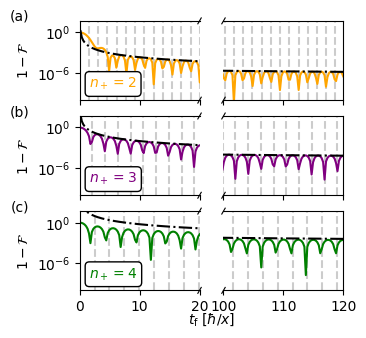

In [5]:
fig = plt.figure(figsize=(3.4, 3.5))

sps = GridSpec(3, 1)

colors = ["orange", "purple", "green"]
baxs = [
    brokenaxes(
        xlims=((0, 20), (100, 120)), subplot_spec=sps[i], despine=False, tilt=60, d=0.01
    )
    for i in range(3)
]

for i in range(len(fidelities)):
    baxs[i].plot(tfs, 1 - fidelities[i], c=colors[i])
    baxs[i].set_yscale("log")

    baxs[i].text(
        0.08,
        0.1,
        rf"$n_+ = {n_plus[i]:.0f}$",
        ha="left",
        transform=baxs[i].axs[0].transAxes,
        c=colors[i],
        va="bottom",
        bbox={"boxstyle": "round", "ec": "k", "fc": "w", "alpha": 1},
    )

    # Envelope in the adiabatic limit
    baxs[i].plot(tfs, 4 * adiabaticities[i] ** 2 / tfs**2, c="k", ls="-.")

    baxs[i].set_ylim(1e-10, 50)

    # Resonances
    baxs[i].vlines(
        np.arange(int(tfs[-1] / periods[i]) + 1) * periods[i],
        *baxs[i].axs[0].get_ylim(),
        ls="--",
        color="k",
        alpha=0.2,
        zorder=0,
    )

    baxs[i].axs[0].set_ylabel(r"$1 - \mathcal{F}$")

for bax in baxs[:2]:
    bax.set_xticklabels([])
baxs[-1].set_xlabel(r"$t_\mathrm{f}\; [\hbar / x]$")

add_labels([bax.axs[0] for bax in baxs], [-0.5, 1.05])